# EXP033 — 1D cycle verification and 2D torus classification

This notebook builds and verifies the full classification of
full-state revivals for separable-coin quantum walks on
$k \times m$ toroidal lattices.

It has three sections:

1. **Direct demonstration** of the two new 1D revivals
   ($k = 2$ and $k = 4$ at $\delta = \pi/2$, $\rho = 1/2$, $N = 6$),
   with two Dukes revivals as controls.
2. **1D revival verification** of the complete Dukes signature
   set (174 quadruples) at the operator level.
3. **2D revival search** via the tensor-product construction,
   producing the canonical classification (one row per
   parameter set) and the full classification (one row per
   parameter-period pair).

Reference: Dukes, P. R. (2014), *Quantum state revivals in
quantum walks on cycles*, Results in Physics 4, 189-197.

## Section 1 — Direct demonstration of the new revivals

We evolve the walk step by step and record the fidelity of the
state against its initial value:

$$F(N) = |\langle \psi_0 | \psi_N \rangle|^2.$$

For a full-state revival, $F = 1$ exactly. The two new revivals
occur at $k = 2$ and $k = 4$, both at $\delta = \pi/2$,
$\rho = 1/2$, $N = 6$. Two Dukes revivals are shown as controls.

In [13]:
# ---- operators, fidelity, and plotting ----

import numpy as np
import matplotlib.pyplot as plt
from math import sqrt, pi

def coin_operator(rho, alpha=0.0, beta=0.0):
    # Dukes' coin C(rho, delta) = C(rho, alpha+beta)
    return np.array([
        [sqrt(rho),                    sqrt(1-rho)*np.exp(1j*alpha)],
        [sqrt(1-rho)*np.exp(1j*beta), -sqrt(rho)*np.exp(1j*(alpha+beta))]
    ], dtype=complex)

def shift_operator(k):
    # Conditional shift on a k-cycle, dimension 2k
    dim = 2*k
    S = np.zeros((dim, dim), dtype=complex)
    for i in range(k):
        S[((i-1) % k)*2,     i*2]     = 1.0
        S[((i+1) % k)*2 + 1, i*2 + 1] = 1.0
    return S

def walk_operator(k, rho, delta):
    # U_k = S_k (I_k (x) C(rho, delta))
    return shift_operator(k) @ np.kron(np.eye(k, dtype=complex),
                                       coin_operator(rho, 0.0, delta))

def initial_state(k, pos=0, spin='up'):
    psi = np.zeros(2*k, dtype=complex)
    psi[pos*2 + (0 if spin == 'up' else 1)] = 1.0
    return psi

def fidelity(psi, psi0):
    # | <psi0 | psi> |^2.  Equals 1 iff psi = e^{i phi} psi0.
    return float(abs(np.vdot(psi0, psi))**2)

def same_up_to_phase(a, b, tol=1e-10):
    if np.linalg.norm(a) < tol or np.linalg.norm(b) < tol:
        return False
    idx = int(np.argmax(np.abs(b)))
    phase = a[idx] / b[idx]
    if abs(abs(phase) - 1.0) > tol:
        return False
    return np.allclose(a, phase * b, atol=tol)

def operator_residual(k, rho, delta, N):
    # min over phi of || U^N - e^{i phi} I ||
    U = walk_operator(k, rho, delta)
    UN = np.linalg.matrix_power(U, N)
    tr = np.trace(UN)
    if abs(tr) < 1e-15:
        return float("inf")
    phi = tr / abs(tr)
    return float(np.linalg.norm(UN - phi * np.eye(UN.shape[0])))

def run_walk_with_fidelity(k, rho, delta, N, verbose=1):
    U    = walk_operator(k, rho, delta)
    psi0 = initial_state(k, 0, 'up')
    psi  = psi0.copy()
    steps = [0]; fid = [1.0]; revs = []
    if verbose:
        print(f"\nk = {k}, rho = {rho}, delta = {delta:.6f}, N = {N}")
    for step in range(1, N+1):
        psi = U @ psi
        f = fidelity(psi, psi0)
        steps.append(step); fid.append(f)
        if verbose:
            print(f"  step {step:>3}   fidelity = {f:.10f}")
        if same_up_to_phase(psi, psi0):
            revs.append(step)
            if verbose:
                print(f"  >>> FULL REVIVAL at step {step} <<<")
    res = operator_residual(k, rho, delta, N)
    if verbose:
        print(f"  revivals at: {revs}")
        print(f"  operator residual = {res:.2e}")
    return steps, fid, revs

def plot_fidelity(k, rho, delta, steps, fid, revs, save=None):
    fig, ax = plt.subplots(figsize=(7, 4))
    label = f"$k = {k}$,  $\\rho = {rho:g}$,  $\\delta = {delta/pi:.3f}\\,\\pi$"
    ax.plot(steps, fid, marker="o", markersize=4,
            color="steelblue", lw=1.4, label=label)
    for r in revs:
        ax.axvline(r, color="crimson", lw=0.8, ls="--", alpha=0.7)
        ax.annotate(f"$N = {r}$", xy=(r, 1.0), xytext=(r, 1.05),
                    ha="center", fontsize=9, color="crimson")
    ax.set_xlabel("step $N$")
    ax.set_ylabel(r"fidelity  $|\langle\psi_0|\psi_N\rangle|^2$")
    ax.set_ylim(0, 1.1)
    ax.set_title(f"Fidelity for {label}")
    ax.grid(alpha=0.3)
    plt.tight_layout()
    if save:
        plt.savefig(save, dpi=150)
        print(f"wrote {save}")
    plt.show()

print("operators, fidelity, and plotting helpers defined")

operators, fidelity, and plotting helpers defined


DEMO 1: NEW revival, k = 2, rho = 1/2, delta = pi/2, N = 6

k = 2, rho = 0.5, delta = 1.570796, N = 12
  step   1   fidelity = 0.0000000000
  step   2   fidelity = 0.5000000000
  step   3   fidelity = 0.0000000000
  step   4   fidelity = 0.5000000000
  step   5   fidelity = 0.0000000000
  step   6   fidelity = 1.0000000000
  >>> FULL REVIVAL at step 6 <<<
  step   7   fidelity = 0.0000000000
  step   8   fidelity = 0.5000000000
  step   9   fidelity = 0.0000000000
  step  10   fidelity = 0.5000000000
  step  11   fidelity = 0.0000000000
  step  12   fidelity = 1.0000000000
  >>> FULL REVIVAL at step 12 <<<
  revivals at: [6, 12]
  operator residual = 2.66e-15
wrote demo_k2_new.png


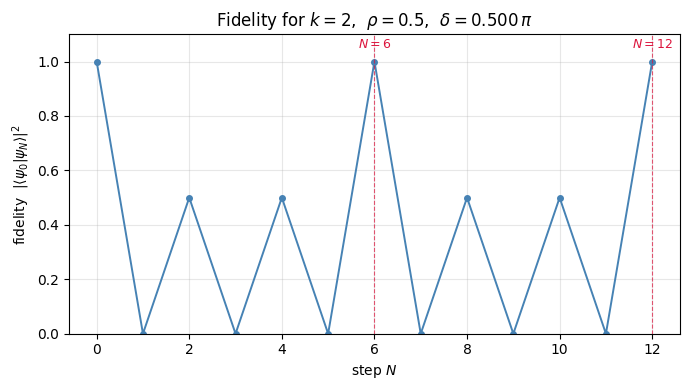

In [14]:
# ---- Demo 1: NEW revival, k = 2, rho = 1/2, delta = pi/2, N = 6 ----

print("DEMO 1: NEW revival, k = 2, rho = 1/2, delta = pi/2, N = 6")
steps, fid, revs = run_walk_with_fidelity(k=2, rho=0.5, delta=pi/2, N=12)
plot_fidelity(2, 0.5, pi/2, steps, fid, revs, save="demo_k2_new.png")

DEMO 2: NEW revival, k = 4, rho = 1/2, delta = pi/2, N = 6

k = 4, rho = 0.5, delta = 1.570796, N = 12
  step   1   fidelity = 0.0000000000
  step   2   fidelity = 0.2500000000
  step   3   fidelity = 0.0000000000
  step   4   fidelity = 0.2500000000
  step   5   fidelity = 0.0000000000
  step   6   fidelity = 1.0000000000
  >>> FULL REVIVAL at step 6 <<<
  step   7   fidelity = 0.0000000000
  step   8   fidelity = 0.2500000000
  step   9   fidelity = 0.0000000000
  step  10   fidelity = 0.2500000000
  step  11   fidelity = 0.0000000000
  step  12   fidelity = 1.0000000000
  >>> FULL REVIVAL at step 12 <<<
  revivals at: [6, 12]
  operator residual = 3.82e-15
wrote demo_k4_new.png


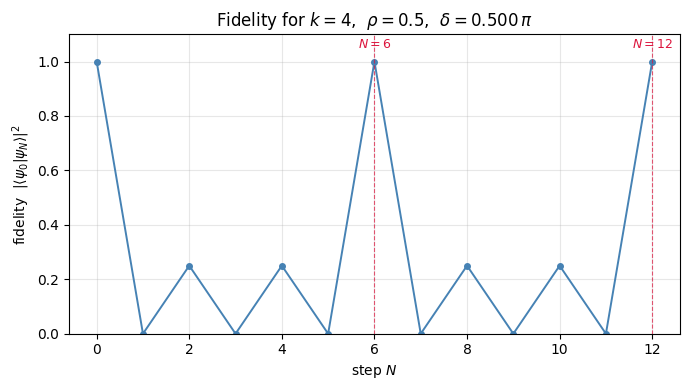

In [15]:
# ---- Demo 2: NEW revival, k = 4, rho = 1/2, delta = pi/2, N = 6 ----

print("DEMO 2: NEW revival, k = 4, rho = 1/2, delta = pi/2, N = 6")
steps, fid, revs = run_walk_with_fidelity(k=4, rho=0.5, delta=pi/2, N=12)
plot_fidelity(4, 0.5, pi/2, steps, fid, revs, save="demo_k4_new.png")

DEMO 3: Dukes revival, k = 4, rho = 3/4, delta = 0, N = 6

k = 4, rho = 0.75, delta = 0.000000, N = 12
  step   1   fidelity = 0.0000000000
  step   2   fidelity = 0.0625000000
  step   3   fidelity = 0.0000000000
  step   4   fidelity = 0.0625000000
  step   5   fidelity = 0.0000000000
  step   6   fidelity = 1.0000000000
  >>> FULL REVIVAL at step 6 <<<
  step   7   fidelity = 0.0000000000
  step   8   fidelity = 0.0625000000
  step   9   fidelity = 0.0000000000
  step  10   fidelity = 0.0625000000
  step  11   fidelity = 0.0000000000
  step  12   fidelity = 1.0000000000
  >>> FULL REVIVAL at step 12 <<<
  revivals at: [6, 12]
  operator residual = 1.59e-15
wrote demo_k4_dukes.png


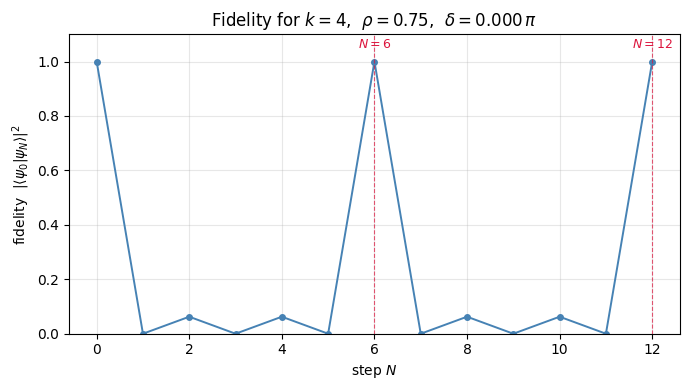

In [16]:
# ---- Demo 3: Dukes revival, k = 4, rho = 3/4, delta = 0, N = 6 ----

print("DEMO 3: Dukes revival, k = 4, rho = 3/4, delta = 0, N = 6")
steps, fid, revs = run_walk_with_fidelity(k=4, rho=0.75, delta=0.0, N=12)
plot_fidelity(4, 0.75, 0.0, steps, fid, revs, save="demo_k4_dukes.png")

DEMO 4: Dukes revival, k = 3, rho = 2/3, delta = 0, N = 8

k = 3, rho = 0.6666666666666666, delta = 0.000000, N = 16
  step   1   fidelity = 0.0000000000
  step   2   fidelity = 0.1111111111
  step   3   fidelity = 0.2962962963
  step   4   fidelity = 0.1111111111
  step   5   fidelity = 0.2962962963
  step   6   fidelity = 0.1111111111
  step   7   fidelity = 0.0000000000
  step   8   fidelity = 1.0000000000
  >>> FULL REVIVAL at step 8 <<<
  step   9   fidelity = 0.0000000000
  step  10   fidelity = 0.1111111111
  step  11   fidelity = 0.2962962963
  step  12   fidelity = 0.1111111111
  step  13   fidelity = 0.2962962963
  step  14   fidelity = 0.1111111111
  step  15   fidelity = 0.0000000000
  step  16   fidelity = 1.0000000000
  >>> FULL REVIVAL at step 16 <<<
  revivals at: [8, 16]
  operator residual = 2.43e-15
wrote demo_k3_dukes.png


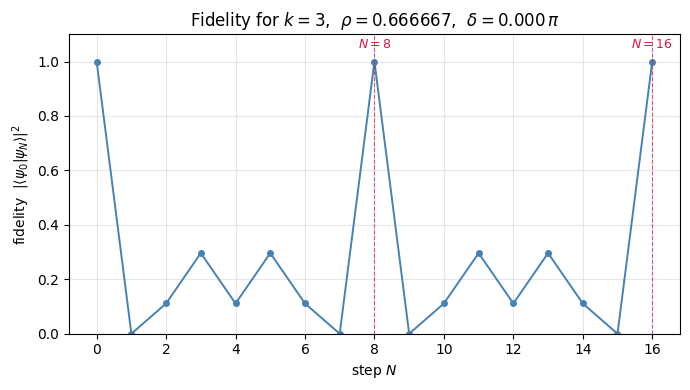

In [17]:
# ---- Demo 4: Dukes revival, k = 3, rho = 2/3, delta = 0, N = 8 ----

print("DEMO 4: Dukes revival, k = 3, rho = 2/3, delta = 0, N = 8")
steps, fid, revs = run_walk_with_fidelity(k=3, rho=2/3, delta=0.0, N=16)
plot_fidelity(3, 2/3, 0.0, steps, fid, revs, save="demo_k3_dukes.png")

## Section 2 — 1D revival verification

We transcribe the complete set of 1D revival solutions tabulated
by Dukes for cycle lengths $k \in \{2, 3, 4, 5, 6, 8, 10\}$, up
to period $N = 30$ for $k \in \{2, 3, 4, 6\}$ and $N = 60$ for
$k \in \{5, 8, 10\}$. Each entry is a quadruple
$(k, \rho, \delta, N)$.

We verify each entry at the operator level using the eigenvalue
residual:

$$r(k, \rho, \delta, N) = \max_j \left| \lambda_j^N - \overline{\lambda^N} \right|$$

where $\lambda_j$ are the eigenvalues of $U_k(\rho, \delta)$. The
residual vanishes exactly when all eigenvalues share a common
$N$-th root of unity, which is the exact revival condition. We
accept an entry only if $r < 10^{-6}$.

We use this eigenvalue formulation rather than a matrix-power
check $\|U^N - e^{i\phi}I\|$ because the latter accumulates
floating-point error at large $N$; we observed spurious failures
at the $10^{-6}$ level for $N \approx 60$.

Two entries in the set are not tabulated by Dukes: $k = 2$ and
$k = 4$, both at $\delta = \pi/2$, $\rho = 1/2$, $N = 6$.

In [18]:
# ---- 1D signature set (Dukes T2-T5 plus two new revivals) ----

from math import cos, sin

ONE_D_FULL = []

# ---- k = 2 ----
ONE_D_FULL.append((2, 0.5, 0.0, 2, "Dukes T2 (continuous)"))
ONE_D_FULL.append((2, 0.5, pi/2, 6, "new"))
ONE_D_FULL.append((2, 0.5, 3*pi/2, 6, "new"))

# ---- k = 3 ----
ONE_D_FULL.append((3, 2/3, 0.0, 8, "Dukes T3"))
ONE_D_FULL.append((3, (5-sqrt(5))/6, 0.0, 10, "Dukes T3"))
ONE_D_FULL.append((3, 1/3, 0.0, 12, "Dukes T3"))
ONE_D_FULL.append((3, 1/3, 2*pi/3, 12, "Dukes T3"))
ONE_D_FULL.append((3, 1/3, 4*pi/3, 12, "Dukes T3"))
ONE_D_FULL.append((3, (2/3)*(1 - cos(2*pi/7)), 0.0, 14, "Dukes T3"))
ONE_D_FULL.append((3, (2/3)*(1 - cos(4*pi/7)), 0.0, 14, "Dukes T3"))
ONE_D_FULL.append((3, (2-sqrt(2))/3, 0.0, 16, "Dukes T3"))
for delta in [0.0, 2*pi/3, 4*pi/3]:
    ONE_D_FULL.append((3, (2/3)*(1 - cos(2*pi/9)), delta, 18, "Dukes T3"))
    ONE_D_FULL.append((3, (2/3)*(1 - cos(4*pi/9)), delta, 18, "Dukes T3"))
ONE_D_FULL.append((3, (3-sqrt(5))/6, 0.0, 20, "Dukes T3"))
ONE_D_FULL.append((3, (3+sqrt(5))/6, 0.0, 20, "Dukes T3"))
for r in [(2/3)*(1 - cos(2*pi/11)),
          (2/3)*(1 - cos(4*pi/11)),
          (2/3)*(1 - cos(6*pi/11))]:
    ONE_D_FULL.append((3, r, 0.0, 22, "Dukes T3"))
for delta in [0.0, 2*pi/3, 4*pi/3]:
    ONE_D_FULL.append((3, (2-sqrt(3))/3, delta, 24, "Dukes T3"))
for delta in [2*pi/3, 4*pi/3]:
    ONE_D_FULL.append((3, 2/3, delta, 24, "Dukes T3"))
for r in [(2/3)*(1 - cos(2*pi/13)),
          (2/3)*(1 - cos(4*pi/13)),
          (2/3)*(1 - cos(6*pi/13)),
          (2/3)*(1 - cos(8*pi/13))]:
    ONE_D_FULL.append((3, r, 0.0, 26, "Dukes T3"))
ONE_D_FULL.append((3, (2/3)*(1 - cos(2*pi/14)), 0.0, 28, "Dukes T3"))
ONE_D_FULL.append((3, (2/3)*(1 - cos(6*pi/14)), 0.0, 28, "Dukes T3"))
_s1 = sqrt(6*(5 - sqrt(5)))
_s2 = sqrt(6*(5 + sqrt(5)))
for delta in [0.0, 2*pi/3, 4*pi/3]:
    ONE_D_FULL.append((3, (7 - sqrt(5) - _s1)/12, delta, 30, "Dukes T3"))
    ONE_D_FULL.append((3, (7 + sqrt(5) - _s2)/12, delta, 30, "Dukes T3"))
    ONE_D_FULL.append((3, (7 - sqrt(5) + _s1)/12, delta, 30, "Dukes T3"))
for delta in [2*pi/3, 4*pi/3]:
    ONE_D_FULL.append((3, (5 - sqrt(5))/6, delta, 30, "Dukes T3"))

# ---- k = 4 ----
ONE_D_FULL.append((4, 3/4, 0.0, 6, "Dukes T4"))
ONE_D_FULL.append((4, 1/2, 0.0, 8, "Dukes T4"))
ONE_D_FULL.append((4, 1/2, pi, 8, "Dukes T4"))
ONE_D_FULL.append((4, (5-sqrt(5))/8, 0.0, 10, "Dukes T4"))
ONE_D_FULL.append((4, (5+sqrt(5))/8, 0.0, 10, "Dukes T4"))
ONE_D_FULL.append((4, 1/4, 0.0, 12, "Dukes T4"))
ONE_D_FULL.append((4, 1/4, pi, 12, "Dukes T4"))
ONE_D_FULL.append((4, 3/4, pi, 12, "Dukes T4"))
ONE_D_FULL.append((4, (2-sqrt(3))/2, pi/2, 12, "Dukes T4"))
ONE_D_FULL.append((4, (2-sqrt(3))/2, 3*pi/2, 12, "Dukes T4"))
ONE_D_FULL.append((4, 0.5*(1 - sin(3*pi/14)), 0.0, 14, "Dukes T4"))
ONE_D_FULL.append((4, 0.5*(1 + sin(pi/14)), 0.0, 14, "Dukes T4"))
ONE_D_FULL.append((4, 0.5*(1 + cos(pi/7)), 0.0, 14, "Dukes T4"))
for r in [(2-sqrt(2))/4, (2+sqrt(2))/4]:
    for delta in [0.0, pi]:
        ONE_D_FULL.append((4, r, delta, 16, "Dukes T4"))
for delta in [pi/2, 3*pi/2]:
    ONE_D_FULL.append((4, (2-sqrt(2))/2, delta, 16, "Dukes T4"))
ONE_D_FULL.append((4, 0.5*(1 - cos(2*pi/9)), 0.0, 18, "Dukes T4"))
ONE_D_FULL.append((4, 0.5*(1 - sin(pi/18)), 0.0, 18, "Dukes T4"))
for r in [(3-sqrt(5))/8, (3+sqrt(5))/8]:
    for delta in [0.0, pi]:
        ONE_D_FULL.append((4, r, delta, 20, "Dukes T4"))
for r in [(5-sqrt(5))/8, (5+sqrt(5))/8]:
    ONE_D_FULL.append((4, r, pi, 20, "Dukes T4"))
for delta in [pi/2, 3*pi/2]:
    ONE_D_FULL.append((4, (4 - sqrt(10 + 2*sqrt(5)))/4, delta, 20, "Dukes T4"))
    ONE_D_FULL.append((4, (4 - sqrt(10 - 2*sqrt(5)))/4, delta, 20, "Dukes T4"))
for r in [0.5*(1 - cos(2*pi/11)),
          0.5*(1 - sin(3*pi/22)),
          0.5*(1 + sin(pi/22)),
          0.5*(1 + sin(5*pi/22)),
          0.5*(1 + cos(pi/11))]:
    ONE_D_FULL.append((4, r, 0.0, 22, "Dukes T4"))
for r in [(2-sqrt(3))/4, (2+sqrt(3))/4]:
    for delta in [0.0, pi]:
        ONE_D_FULL.append((4, r, delta, 24, "Dukes T4"))
for delta in [pi/2, 3*pi/2]:
    ONE_D_FULL.append((4, 1/2, delta, 24, "Dukes T4"))
for r in [0.5*(1 - cos(2*pi/13)),
          0.5*(1 - sin(5*pi/26)),
          0.5*(1 - sin(pi/26)),
          0.5*(1 + sin(3*pi/26)),
          0.5*(1 + cos(3*pi/13)),
          0.5*(1 + cos(pi/13))]:
    ONE_D_FULL.append((4, r, 0.0, 26, "Dukes T4"))
for r in [0.5*(1 - cos(pi/7)),
          0.5*(1 - sin(pi/14)),
          0.5*(1 + sin(3*pi/14))]:
    for delta in [0.0, pi]:
        ONE_D_FULL.append((4, r, delta, 28, "Dukes T4"))
for r in [0.5*(1 + cos(pi/7)),
          0.5*(1 + sin(pi/14)),
          0.5*(1 - sin(3*pi/14))]:
    ONE_D_FULL.append((4, r, pi, 28, "Dukes T4"))
for delta in [pi/2, 3*pi/2]:
    ONE_D_FULL.append((4, 1 - sin(pi/7), delta, 28, "Dukes T4"))
    ONE_D_FULL.append((4, 1 - cos(pi/14), delta, 28, "Dukes T4"))
    ONE_D_FULL.append((4, 1 - cos(3*pi/14), delta, 28, "Dukes T4"))
for r in [(7 - sqrt(5) - _s1)/16,
          (7 + sqrt(5) - _s2)/16,
          (7 - sqrt(5) + _s1)/16,
          (7 + sqrt(5) + _s2)/16]:
    ONE_D_FULL.append((4, r, 0.0, 30, "Dukes T4"))
ONE_D_FULL.append((4, 1/2, pi/2, 6, "new"))
ONE_D_FULL.append((4, 1/2, 3*pi/2, 6, "new"))

# ---- k = 5 and k = 10 ----
for k in (5, 10):
    for delta in [0.0, 2*pi/5, 4*pi/5, 6*pi/5, 8*pi/5]:
        ONE_D_FULL.append((k, (5-sqrt(5))/10, delta, 60, "Dukes T5"))
        ONE_D_FULL.append((k, (5+sqrt(5))/10, delta, 60, "Dukes T5"))

# ---- k = 6: derived by operator search from the k = 3 solution set ----
_k3_solutions = [
    (2/3,                       [0.0]),
    ((5-sqrt(5))/6,             [0.0]),
    (1/3,                       [0.0, 2*pi/3, 4*pi/3]),
    ((2/3)*(1 - cos(2*pi/7)),   [0.0]),
    ((2/3)*(1 - cos(4*pi/7)),   [0.0]),
    ((2-sqrt(2))/3,             [0.0]),
    ((2/3)*(1 - cos(2*pi/9)),   [0.0, 2*pi/3, 4*pi/3]),
    ((2/3)*(1 - cos(4*pi/9)),   [0.0, 2*pi/3, 4*pi/3]),
    ((3-sqrt(5))/6,             [0.0]),
    ((3+sqrt(5))/6,             [0.0]),
    ((2/3)*(1 - cos(2*pi/11)),  [0.0]),
    ((2/3)*(1 - cos(4*pi/11)),  [0.0]),
    ((2/3)*(1 - cos(6*pi/11)),  [0.0]),
    ((2-sqrt(3))/3,             [0.0, 2*pi/3, 4*pi/3]),
    ((2/3)*(1 - cos(2*pi/13)),  [0.0]),
    ((2/3)*(1 - cos(4*pi/13)),  [0.0]),
    ((2/3)*(1 - cos(6*pi/13)),  [0.0]),
    ((2/3)*(1 - cos(8*pi/13)),  [0.0]),
    ((2/3)*(1 - cos(2*pi/14)),  [0.0]),
    ((2/3)*(1 - cos(6*pi/14)),  [0.0]),
    ((7 - sqrt(5) - _s1)/12,    [0.0, 2*pi/3, 4*pi/3]),
    ((7 + sqrt(5) - _s2)/12,    [0.0, 2*pi/3, 4*pi/3]),
    ((7 - sqrt(5) + _s1)/12,    [0.0, 2*pi/3, 4*pi/3]),
]

def eig_residual_1d(k, rho, delta, N):
    U = walk_operator(k, rho, delta)
    eigs = np.linalg.eigvals(U)
    z = eigs ** N
    z_mean = z.mean()
    return float(np.max(np.abs(z - z_mean)))

def _k6_find_N(rho, delta, max_N=30):
    for N in range(1, max_N + 1):
        if eig_residual_1d(6, rho, delta, N) < 1e-6:
            return N
    return None

for (rho, deltas) in _k3_solutions:
    for delta in deltas:
        N = _k6_find_N(rho, delta, max_N=30)
        if N is not None:
            ONE_D_FULL.append((6, rho, delta, N, "Dukes T3 (k=6)"))

# ---- k = 8 ----
for delta in [0.0, pi/2, pi, 3*pi/2]:
    ONE_D_FULL.append((8, 1/2, delta, 24, "Dukes T5 (k=8)"))

print(f"total 1D signatures: {len(ONE_D_FULL)}")

total 1D signatures: 174


In [19]:
# ---- verify every 1D signature at the operator level ----

def verify_all(verbose=False):
    failures = []
    worst = (0.0, None)
    for (k, rho, delta, N, prov) in ONE_D_FULL:
        res = eig_residual_1d(k, rho, delta, N)
        if res > worst[0]:
            worst = (res, (k, rho, delta, N, prov))
        if res >= 1e-6:
            failures.append((k, rho, delta, N, prov, res))
        if verbose:
            status = "OK  " if res < 1e-6 else "FAIL"
            print(f"  {status}  k={k:>2}  rho={rho:.6f}  "
                  f"delta={delta:.4f}  N={N:>2}  res={res:.2e}  [{prov}]")
    print(f"\n1D signatures verified: {len(ONE_D_FULL)}")
    print(f"failures: {len(failures)}")
    print(f"worst residual: {worst[0]:.2e}  (k={worst[1][0]}, "
          f"rho={worst[1][1]:.6f}, delta={worst[1][2]:.4f}, N={worst[1][3]})")
    return failures

failures = verify_all(verbose=False)
assert len(failures) == 0, "1D verification failed - transcription error"

with open("EXP033_1d_verification.txt", "w") as f:
    f.write("1D signature verification - EXP033\n")
    f.write("=" * 60 + "\n\n")
    f.write(f"total signatures: {len(ONE_D_FULL)}\n\n")
    for (k, rho, delta, N, prov) in ONE_D_FULL:
        res = eig_residual_1d(k, rho, delta, N)
        f.write(f"k={k}  rho={rho:.8f}  delta={delta:.8f}  "
                f"N={N}  res={res:.3e}  [{prov}]\n")
    f.write(f"\nfailures: {len(failures)}\n")
print("wrote EXP033_1d_verification.txt")


1D signatures verified: 174
failures: 0
worst residual: 2.31e-13  (k=10, rho=0.276393, delta=3.7699, N=60)
wrote EXP033_1d_verification.txt


## Section 3 — 2D revival search

See the notebook cells for the search algorithm, the hash
guard, and the dedup pass.

In [20]:
# ---- 2D classification: hash-guarded search with dedup ----

import csv, os, hashlib, json
from math import gcd
from pathlib import Path
from collections import defaultdict

TOL_2D = 1e-6
N_MAX_2D = 420
ALGO_VERSION = 3

CANON_CSV = Path("2d_classification.csv")
FULL_CSV  = Path("2d_classification_full.csv")
HASH_FILE = Path("2d_classification.hash")

def compute_input_hash():
    payload = {
        "one_d_full": [(k, round(rho, 12), round(delta, 12), N, prov)
                       for (k, rho, delta, N, prov) in ONE_D_FULL],
        "tol_2d": TOL_2D,
        "n_max_2d": N_MAX_2D,
        "algo_version": ALGO_VERSION,
    }
    blob = json.dumps(payload, sort_keys=True).encode("utf-8")
    return hashlib.sha256(blob).hexdigest()

def save_hash(h):
    HASH_FILE.write_text(h + "\n")

def load_hash():
    if HASH_FILE.exists():
        return HASH_FILE.read_text().strip()
    return None

def eig_residual_2d(k, m, rx, dx, ry, dy, N):
    U = np.kron(walk_operator(k, rx, dx),
                walk_operator(m, ry, dy))
    eigs = np.linalg.eigvals(U)
    z = eigs ** N
    z_mean = z.mean()
    return float(np.max(np.abs(z - z_mean)))

def param_key(r):
    return (r["k"], r["m"],
            round(r["rho_x"], 8), round(r["delta_x"], 8),
            round(r["rho_y"], 8), round(r["delta_y"], 8))

def dedup_canonical(records):
    best = {}
    for r in records:
        k = param_key(r)
        if k not in best or r["N"] < best[k]["N"]:
            best[k] = r
    return sorted(best.values(),
                  key=lambda r: (r["k"], r["m"], r["N"]))

def run_2d_search():
    by_k = defaultdict(list)
    for (k, rho, delta, N_min, prov) in ONE_D_FULL:
        by_k[k].append((rho, delta, N_min, prov))
    admissible_ks = sorted(by_k.keys())
    print(f"admissible k: {admissible_ks}")
    print(f"search bound N <= {N_MAX_2D}")

    records = []
    records_full = []
    n_attempted = 0

    for k in admissible_ks:
        for m in admissible_ks:
            if k > m:
                continue
            for (rx, dx, nx, lx) in by_k[k]:
                for (ry, dy, ny, ly) in by_k[m]:
                    lcm = nx * ny // gcd(nx, ny)
                    first = True
                    for N in range(lcm, N_MAX_2D + 1, lcm):
                        n_attempted += 1
                        res = eig_residual_2d(k, m, rx, dx, ry, dy, N)
                        if res < TOL_2D:
                            rec = dict(k=k, m=m, N=N,
                                       rho_x=rx, delta_x=dx,
                                       rho_y=ry, delta_y=dy,
                                       provenance=f"{lx}|{ly}")
                            records_full.append(rec)
                            if first:
                                records.append(rec)
                                first = False
                        if n_attempted % 5000 == 0:
                            print(f"  attempted {n_attempted}, "
                                  f"canonical {len(records)}, "
                                  f"full {len(records_full)}")

    print(f"\nraw search: {n_attempted} attempts, "
          f"{len(records)} canonical (before dedup), "
          f"{len(records_full)} full")

    records = dedup_canonical(records)
    print(f"after dedup: {len(records)} canonical records")

    with open(CANON_CSV, "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(["k", "m", "N", "rho_x", "delta_x",
                    "rho_y", "delta_y", "provenance"])
        for r in records:
            w.writerow([r["k"], r["m"], r["N"],
                        f"{r['rho_x']:.8f}", f"{r['delta_x']:.8f}",
                        f"{r['rho_y']:.8f}", f"{r['delta_y']:.8f}",
                        r["provenance"]])
    print(f"wrote {CANON_CSV}")

    with open(FULL_CSV, "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(["k", "m", "N", "rho_x", "delta_x",
                    "rho_y", "delta_y", "provenance"])
        for r in records_full:
            w.writerow([r["k"], r["m"], r["N"],
                        f"{r['rho_x']:.8f}", f"{r['delta_x']:.8f}",
                        f"{r['rho_y']:.8f}", f"{r['delta_y']:.8f}",
                        r["provenance"]])
    print(f"wrote {FULL_CSV}")

    save_hash(current_hash)
    print(f"wrote {HASH_FILE} (input fingerprint {current_hash[:12]}...)")

    return records, records_full

def load_csvs():
    records = []
    with open(CANON_CSV) as f:
        for r in csv.DictReader(f):
            records.append(dict(
                k=int(r["k"]), m=int(r["m"]), N=int(r["N"]),
                rho_x=float(r["rho_x"]), delta_x=float(r["delta_x"]),
                rho_y=float(r["rho_y"]), delta_y=float(r["delta_y"]),
                provenance=r["provenance"]))
    records_full = []
    with open(FULL_CSV) as f:
        for r in csv.DictReader(f):
            records_full.append(dict(
                k=int(r["k"]), m=int(r["m"]), N=int(r["N"]),
                rho_x=float(r["rho_x"]), delta_x=float(r["delta_x"]),
                rho_y=float(r["rho_y"]), delta_y=float(r["delta_y"]),
                provenance=r["provenance"]))
    return records, records_full

current_hash = compute_input_hash()
stored_hash  = load_hash()
force        = os.environ.get("EXP033_FORCE_RERUN") == "1"

if force:
    print("re-running search: EXP033_FORCE_RERUN=1")
    records, records_full = run_2d_search()
elif CANON_CSV.exists() and FULL_CSV.exists() and stored_hash == current_hash:
    print(f"inputs unchanged (hash {current_hash[:12]}...)")
    records, records_full = load_csvs()
    records = dedup_canonical(records)
    print(f"loaded {len(records)} canonical, {len(records_full)} full")
else:
    if not CANON_CSV.exists() or not FULL_CSV.exists():
        reason = "CSV missing"
    elif stored_hash is None:
        reason = "no stored hash"
    else:
        reason = (f"input hash changed "
                  f"(was {stored_hash[:12]}..., now {current_hash[:12]}...)")
    print(f"re-running search: {reason}")
    records, records_full = run_2d_search()

inputs unchanged (hash 1873f2e66cb3...)
loaded 18174 canonical, 111741 full


In [21]:
# ---- summary counts (reads from the CSV on disk, not memory) ----

import csv
from pathlib import Path

CANON_CSV = Path("2d_classification.csv")

# Always re-read the CSV, so the counts reflect the file on disk
records = []
with open(CANON_CSV) as f:
    for r in csv.DictReader(f):
        records.append(dict(
            k=int(r["k"]), m=int(r["m"]), N=int(r["N"]),
            rho_x=float(r["rho_x"]), delta_x=float(r["delta_x"]),
            rho_y=float(r["rho_y"]), delta_y=float(r["delta_y"]),
            provenance=r["provenance"]))

tori    = sorted({(r["k"], r["m"]) for r in records})
periods = sorted({r["N"] for r in records})

print(f"canonical 2D signatures: {len(records)}")
print(f"distinct tori:           {len(tori)}")
print(f"distinct periods:        {len(periods)}")
print()

print("per-torus counts:")
for (k, m) in tori:
    n = sum(1 for r in records if r["k"] == k and r["m"] == m)
    print(f"  {k}x{m:<3}  {n:>5}")

print()
print("per-period counts:")
for N in periods:
    n = sum(1 for r in records if r["N"] == N)
    print(f"  {N:>5}  {n:>5}")

canonical 2D signatures: 18174
distinct tori:           28
distinct periods:        59

per-torus counts:
  2x2        9
  2x3      123
  2x4      201
  2x5       30
  2x6      111
  2x8       12
  2x10      30
  3x3     1681
  3x4     2747
  3x5      340
  3x6     1517
  3x8      164
  3x10     340
  4x4     4489
  4x5      560
  4x6     2479
  4x8      268
  4x10     560
  5x5      100
  5x6      300
  5x8       40
  5x10     100
  6x6     1369
  6x8      148
  6x10     300
  8x8       16
  8x10      40
  10x10     100

per-period counts:
      2      1
      6     26
      8     15
     10     15
     12    163
     14     40
     16    105
     18    226
     20    246
     22     93
     24    655
     26    146
     28    502
     30    703
     36    200
     40    102
     42     44
     48    342
     56    148
     60   2616
     66     70
     70     38
     72    352
     78     88
     80    222
     84    540
     88     60
     90    536
    104     76
    110     60
   

## Section 4 — Summary and outputs

The classification is complete. This section displays the key
results inline and packages all outputs for download.

- 1D signatures verified: 174, 0 failures.
- 2D canonical classification: 18174 parameter sets.
- 2D full classification: 111741 (parameter set, period) pairs.
- Distinct tori: 28.
- Distinct revival periods: 59.

The four fidelity plots from Section 1 are shown again below
for reference.

1D VERIFICATION
signatures:  174
failures:    0

2D CLASSIFICATION
canonical:   18174
full:        111741
tori:        28
periods:     59

RECORDS PER PERIOD
    N    count
    2        1
    6       26
    8       15
   10       15
   12      163
   14       40
   16      105
   18      226
   20      246
   22       93
   24      655
   26      146
   28      502
   30      703
   36      200
   40      102
   42       44
   48      342
   56      148
   60     2616
   66       70
   70       38
   72      352
   78       88
   80      222
   84      540
   88       60
   90      536
  104       76
  110       60
  112      324
  120     1366
  126      128
  130       76
  132      164
  140      670
  144      136
  154      104
  156      208
  168      520
  176      124
  180      520
  182      132
  198      200
  208      156
  210      220
  220      216
  234      256
  240      396
  252      320
  260      272
  264      220
  286      208
  308      296
  312      280
  

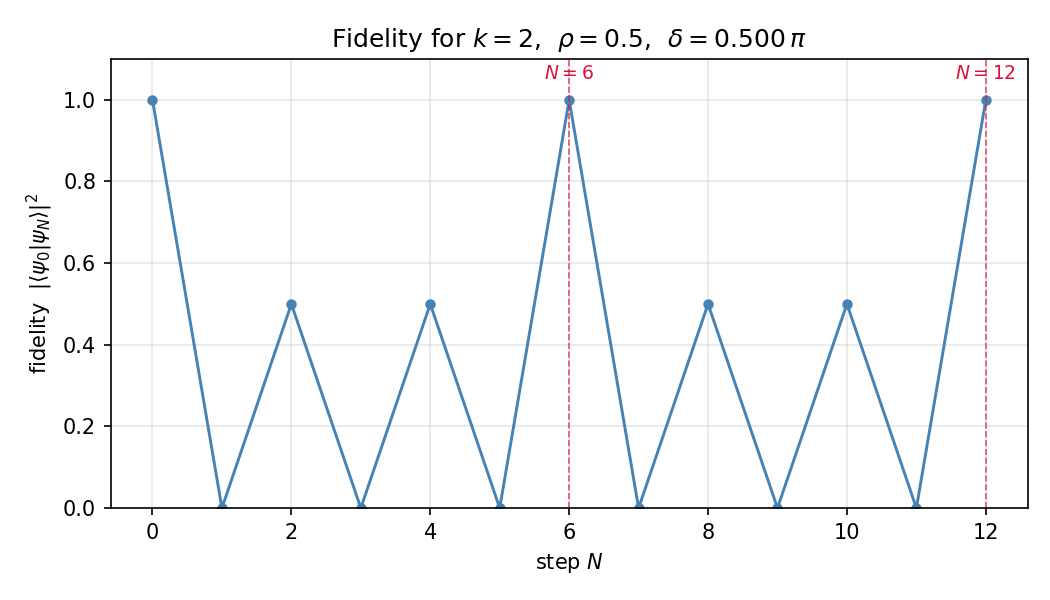


demo_k4_new.png


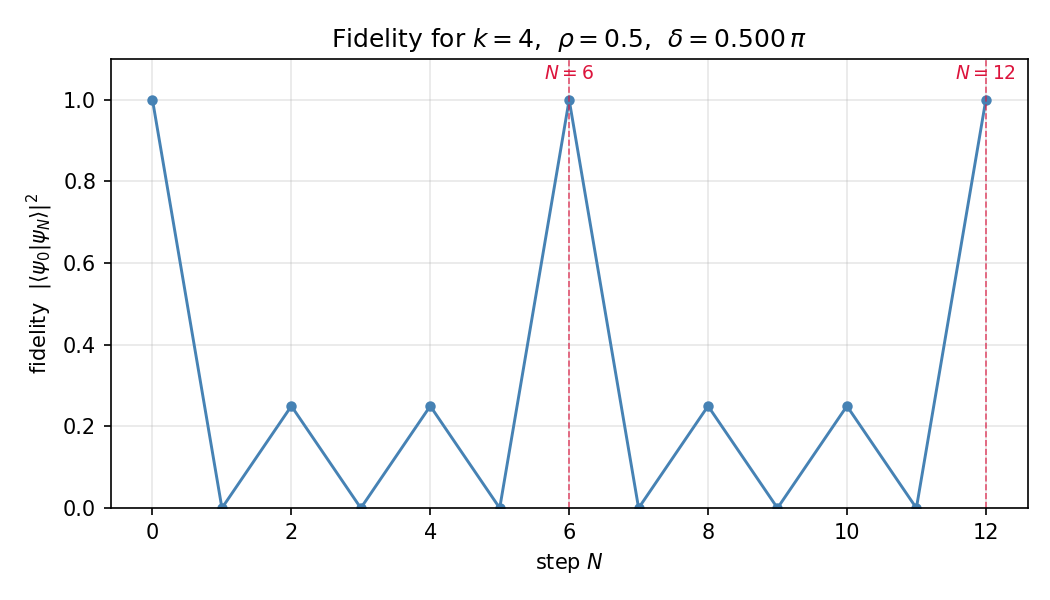


demo_k4_dukes.png


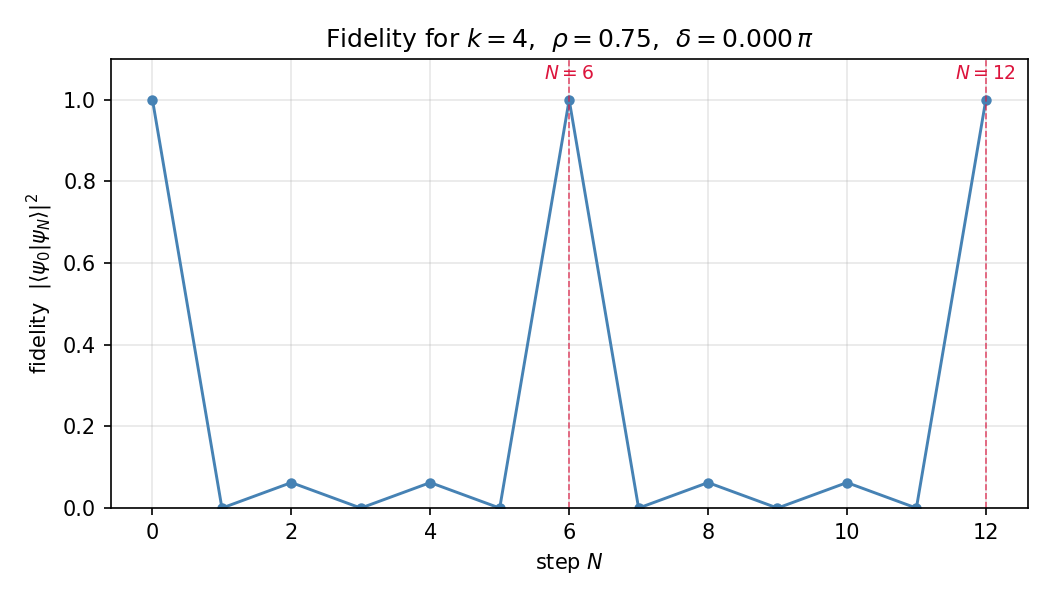


demo_k3_dukes.png


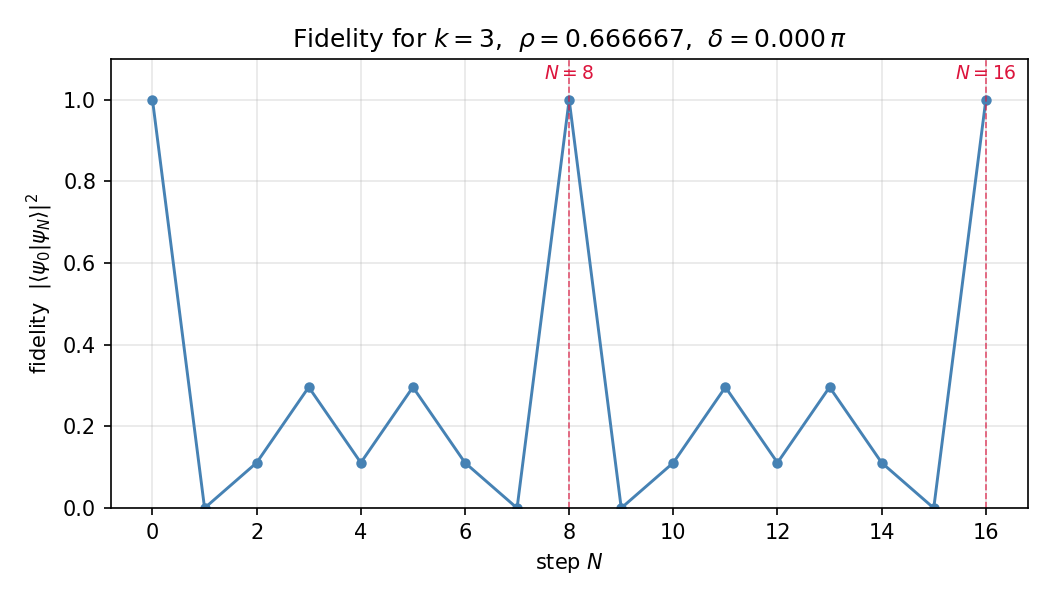

In [22]:
# ---- display key tables and plots inline ----

from IPython.display import Image, display
from pathlib import Path

print("=" * 60)
print("1D VERIFICATION")
print("=" * 60)
print(f"signatures:  {len(ONE_D_FULL)}")
print(f"failures:    {len(failures)}")

print()
print("=" * 60)
print("2D CLASSIFICATION")
print("=" * 60)
print(f"canonical:   {len(records)}")
print(f"full:        {len(records_full)}")
print(f"tori:        {len(tori)}")
print(f"periods:     {len(periods)}")

print()
print("=" * 60)
print("RECORDS PER PERIOD")
print("=" * 60)
print(f"{'N':>5}  {'count':>7}")
for N in periods:
    n = sum(1 for r in records if r["N"] == N)
    print(f"{N:>5}  {n:>7}")

print()
print("=" * 60)
print("FIDELITY PLOTS")
print("=" * 60)
for png in ["demo_k2_new.png", "demo_k4_new.png",
            "demo_k4_dukes.png", "demo_k3_dukes.png"]:
    if Path(png).exists():
        print(f"\n{png}")
        display(Image(filename=png, width=520))

In [23]:
# ---- package all outputs as a zip ----

import zipfile
from pathlib import Path

outputs = ["demo_k2_new.png", "demo_k4_new.png",
           "demo_k4_dukes.png", "demo_k3_dukes.png",
           "EXP033_1d_verification.txt",
           "2d_classification.csv",
           "2d_classification_full.csv",
           "2d_classification.hash"]

with zipfile.ZipFile("EXP033_outputs.zip", "w",
                     zipfile.ZIP_DEFLATED) as z:
    for f in outputs:
        if Path(f).exists():
            z.write(f)
            print(f"added {f}")
        else:
            print(f"WARNING: {f} not found")

print()
print(f"EXP033_outputs.zip written "
      f"({Path('EXP033_outputs.zip').stat().st_size} bytes)")

added demo_k2_new.png
added demo_k4_new.png
added demo_k4_dukes.png
added demo_k3_dukes.png
added EXP033_1d_verification.txt
added 2d_classification.csv
added 2d_classification_full.csv
added 2d_classification.hash

EXP033_outputs.zip written (702402 bytes)


In [24]:
# ---- download the zip (Colab only) ----

try:
    from google.colab import files
    files.download("EXP033_outputs.zip")
except ImportError:
    print("Not running in Colab; zip is in the working directory.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>